In [5]:
import pandas as pd
import os 

raw_data_filenames = os.listdir("/home/marito/Documents/Projects/forest-fire-detection/data/raw")

raw_data_paths = [os.path.join("/home/marito/Documents/Projects/forest-fire-detection/data/raw", filename) for filename in raw_data_filenames]

test = raw_data_paths[0]

full_data = pd.concat([pd.read_excel(path) for path in raw_data_paths])

full_data.head(), full_data.columns


(   Campania  NumeroParte            Estado Comunidad Provincia  \
 0      2023   2023010001  Cerrado Revisión   EUSKADI     ALAVA   
 1      2023   2023010002  Cerrado Revisión   EUSKADI     ALAVA   
 2      2023   2023010003  Cerrado Revisión   EUSKADI     ALAVA   
 3      2023   2023010004  Cerrado Revisión   EUSKADI     ALAVA   
 4      2023   2023010005  Cerrado Revisión   EUSKADI     ALAVA   
 
                 Municipio    ComarcaIsla          EntidadMenor  \
 0                 ELCIEGO  RIOJA ALAVESA               ELCIEGO   
 1      LANTZIEGO/LANCIEGO  RIOJA ALAVESA    LANCIEGO/LANTZIEGO   
 2     LAPUEBLA DE LABARCA  RIOJA ALAVESA  LAPUEBLA DE  LABARCA   
 3      LANTZIEGO/LANCIEGO  RIOJA ALAVESA    LANCIEGO/LANTZIEGO   
 4  URIZAHARRA-PEÑACERRADA        MONTAÑA                  LOZA   
 
    NumeroMunicipiosAfectados  Hoja  ... SuperficieNoArbolada  \
 0                          1   602  ...               2,0600   
 1                          1   602  ...               1,4400 

In [6]:
full_data["Detectado"] = pd.to_datetime(full_data["Detectado"], format="%d/%m/%Y %H:%M:%S")

full_data["Detectado"].min(), full_data["Detectado"].max()

full_data.to_csv(f"/home/marito/Documents/Projects/forest-fire-detection/data/processed/data_processed_{full_data['Detectado'].min()}_{full_data['Detectado'].max()}.csv", index=False)

In [10]:
import os
import pandas as pd

processed_data_filename = os.listdir("/home/marito/Documents/Projects/forest-fire-detection/data/processed/")

processed_data_path = f"/home/marito/Documents/Projects/forest-fire-detection/data/processed/{processed_data_filename[0]}"
processed_data = pd.read_csv(processed_data_path, parse_dates=True)
processed_data.head()

,Campania,NumeroParte,Estado,Comunidad,Provincia,Municipio,ComarcaIsla,EntidadMenor,NumeroMunicipiosAfectados,Hoja,...,SuperficieNoArbolada,SuperficieTotalForestal,SuperficieAgricola,OtrasSuperficiesNoforestales,AfectoZonasInterfazUrbanoForestal,TipoInterfazAfectado,AfectoEspacioProtegido,AfectoTierrasAgrarias,AfectoZar,NumeroPartePss
0,2023,2023010001,Cerrado Revisión,EUSKADI,ALAVA,ELCIEGO,RIOJA ALAVESA,ELCIEGO,1,602,...,"2,0600","2,0600","0,0000","0,0000",No,,No,No,No,
1,2023,2023010002,Cerrado Revisión,EUSKADI,ALAVA,LANTZIEGO/LANCIEGO,RIOJA ALAVESA,LANCIEGO/LANTZIEGO,1,602,...,"1,4400","1,4400","0,0000","0,0000",No,,No,No,No,
2,2023,2023010003,Cerrado Revisión,EUSKADI,ALAVA,LAPUEBLA DE LABARCA,RIOJA ALAVESA,LAPUEBLA DE LABARCA,1,602,...,"0,3400","0,3400","0,0000","0,0000",No,,No,No,No,
3,2023,2023010004,Cerrado Revisión,EUSKADI,ALAVA,LANTZIEGO/LANCIEGO,RIOJA ALAVESA,LANCIEGO/LANTZIEGO,1,602,...,"0,4800","0,4800","0,0000","0,0000",No,,No,No,No,
4,2023,2023010005,Cerrado Revisión,EUSKADI,ALAVA,URIZAHARRA-PEÑACERRADA,MONTAÑA,LOZA,1,601,...,"0,0700","0,0700","0,0000","0,0000",No,,No,No,No,


In [11]:
processed_data.columns

Index(['Campania', 'NumeroParte', 'Estado', 'Comunidad', 'Provincia',
       'Municipio', 'ComarcaIsla', 'EntidadMenor', 'NumeroMunicipiosAfectados',
       'Hoja', 'Cuadricula', 'Huso', 'CoordenadaX', 'CoordenadaY', 'Datum',
       'NumeroPuntosInicioIncendio', 'Detectado', 'Extinguido', 'Causa',
       'Motivacion', 'SuperficieArbolada', 'SuperficieNoArbolada',
       'SuperficieTotalForestal', 'SuperficieAgricola',
       'OtrasSuperficiesNoforestales', 'AfectoZonasInterfazUrbanoForestal',
       'TipoInterfazAfectado', 'AfectoEspacioProtegido',
       'AfectoTierrasAgrarias', 'AfectoZar', 'NumeroPartePss'],
      dtype='str')

In [12]:
surface_columns = [column for column in processed_data.columns if "Superficie" in column]
useful_columns = ["NumeroParte", "Comunidad", "Provincia", "Municipio", "ComarcaIsla", "EntidadMenor", "NumeroMunicipiosAfectados",
                  "Cuadricula", "Huso", "CoordenadaX", "CoordenadaY", "Datum", "NumeroPuntosInicioIncendio", "Detectado", "Extinguido",
                  "Causa", "TipoInterfazAfectado"] + surface_columns

processed_filtered_data = processed_data[useful_columns]
processed_filtered_data.head()


,NumeroParte,Comunidad,Provincia,Municipio,ComarcaIsla,EntidadMenor,NumeroMunicipiosAfectados,Cuadricula,Huso,CoordenadaX,...,NumeroPuntosInicioIncendio,Detectado,Extinguido,Causa,TipoInterfazAfectado,SuperficieArbolada,SuperficieNoArbolada,SuperficieTotalForestal,SuperficieAgricola,OtrasSuperficiesNoforestales
0,2023010001,EUSKADI,ALAVA,ELCIEGO,RIOJA ALAVESA,ELCIEGO,1,B06,30,532928,...,1,2023-01-01,01/01/2023 20:41:00,[400] Intencionado,,"0,0000","2,0600","2,0600","0,0000","0,0000"
1,2023010002,EUSKADI,ALAVA,LANTZIEGO/LANCIEGO,RIOJA ALAVESA,LANCIEGO/LANTZIEGO,1,B07,30,542422,...,1,2023-02-12,12/02/2023 20:55:00,[400] Intencionado,,"0,0000","1,4400","1,4400","0,0000","0,0000"
2,2023010003,EUSKADI,ALAVA,LAPUEBLA DE LABARCA,RIOJA ALAVESA,LAPUEBLA DE LABARCA,1,B06,30,535812,...,1,2023-02-20,20/02/2023 18:19:00,[400] Intencionado,,"0,0000","0,3400","0,3400","0,0000","0,0000"
3,2023010004,EUSKADI,ALAVA,LANTZIEGO/LANCIEGO,RIOJA ALAVESA,LANCIEGO/LANTZIEGO,1,A06,30,539423,...,1,2023-03-01,01/03/2023 18:41:00,"[213] Quema de restos agrícolas (viñas,etc)",,"0,0000","0,4800","0,4800","0,0000","0,0000"
4,2023010005,EUSKADI,ALAVA,URIZAHARRA-PEÑACERRADA,MONTAÑA,LOZA,1,O05,30,526631,...,1,2023-03-20,20/03/2023 18:27:00,[400] Intencionado,,"0,0000","0,0700","0,0700","0,0000","0,0000"


In [14]:
# Typing the useful columns for preprocessing
useful_columns_typing = {
    "NumeroParte": str,
    "Comunidad": str,
    "Provincia": str,
    "Municipio": str,
    "ComarcaIsla": str,
    "EntidadMenor": str,
    "NumeroMunicipiosAfectados": int,
    "Cuadricula": str,
    "Huso": int,
    "CoordenadaX": float,
    "CoordenadaY": float,
    "Datum": str,
    "NumeroPuntosInicioIncendio": int,
    "Causa": str,
    "TipoInterfazAfectado": str,
    "SuperficieArbolada": float,
    "SuperficieNoArbolada": float,
    "SuperficieTotalForestal": float,
    "SuperficieAgricola": float,
    "OtrasSuperficiesNoforestales": float
}

processed_typed_data = processed_filtered_data.copy()

for column, dtype in useful_columns_typing.items():
    if dtype is float:
        values = (
            processed_typed_data[column]
            .astype("string")
            .str.strip()
            .str.replace(",", ".", regex=False)
        )
        processed_typed_data[column] = pd.to_numeric(values, errors="coerce")

processed_typed_data = processed_typed_data.astype(useful_columns_typing)
processed_typed_data["Detectado"] = pd.to_datetime(processed_typed_data["Detectado"])
processed_typed_data["Extinguido"] = pd.to_datetime(processed_typed_data["Extinguido"], format="%d/%m/%Y %H:%M:%S")

In [15]:
processed_typed_data

,NumeroParte,Comunidad,Provincia,Municipio,ComarcaIsla,EntidadMenor,NumeroMunicipiosAfectados,Cuadricula,Huso,CoordenadaX,...,NumeroPuntosInicioIncendio,Detectado,Extinguido,Causa,TipoInterfazAfectado,SuperficieArbolada,SuperficieNoArbolada,SuperficieTotalForestal,SuperficieAgricola,OtrasSuperficiesNoforestales
0,2023010001,EUSKADI,ALAVA,ELCIEGO,RIOJA ALAVESA,ELCIEGO,1,B06,30,532928.0,...,1,2023-01-01,2023-01-01 20:41:00,[400] Intencionado,,0.00,2.06,2.06,0.00,0.0
1,2023010002,EUSKADI,ALAVA,LANTZIEGO/LANCIEGO,RIOJA ALAVESA,LANCIEGO/LANTZIEGO,1,B07,30,542422.0,...,1,2023-02-12,2023-02-12 20:55:00,[400] Intencionado,,0.00,1.44,1.44,0.00,0.0
2,2023010003,EUSKADI,ALAVA,LAPUEBLA DE LABARCA,RIOJA ALAVESA,LAPUEBLA DE LABARCA,1,B06,30,535812.0,...,1,2023-02-20,2023-02-20 18:19:00,[400] Intencionado,,0.00,0.34,0.34,0.00,0.0
3,2023010004,EUSKADI,ALAVA,LANTZIEGO/LANCIEGO,RIOJA ALAVESA,LANCIEGO/LANTZIEGO,1,A06,30,539423.0,...,1,2023-03-01,2023-03-01 18:41:00,"[213] Quema de restos agrícolas (viñas,etc)",,0.00,0.48,0.48,0.00,0.0
4,2023010005,EUSKADI,ALAVA,URIZAHARRA-PEÑACERRADA,MONTAÑA,LOZA,1,O05,30,526631.0,...,1,2023-03-20,2023-03-20 18:27:00,[400] Intencionado,,0.00,0.07,0.07,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56761,2021509002,ARAGON,ZARAGOZA,BUJARALOZ,MONEGROS,BUJARALOZ,1,Q05,30,741693.0,...,1,2021-06-24,2021-06-24 21:00:00,[331] Maquinaria (cosechadoras),,0.00,0.60,0.60,5.88,0.0
56762,2021509003,ARAGON,ZARAGOZA,MURILLO DE GÁLLEGO,HOYA DE HUESCA/PLANA DE UESCA,,1,C09,30,685812.0,...,1,2021-07-04,2021-07-04 17:35:00,[250] Fumadores,,0.01,0.01,0.02,0.13,0.0
56763,2021509004,ARAGON,ZARAGOZA,BUJARALOZ,MONEGROS,,1,P04,30,737679.0,...,1,2021-07-08,2021-07-08 13:00:00,[326] Transformadores de la red eléctrica,,0.01,0.01,0.02,0.00,0.0
56764,2021509005,ARAGON,ZARAGOZA,"ALMOLDA, LA",MONEGROS,LA ALMOLDA,1,O04,30,731492.0,...,1,2021-07-14,2021-07-14 15:55:00,[331] Maquinaria (cosechadoras),,0.00,0.39,0.39,1.66,0.0


In [1]:
from forest_fire_detection.load import SatelliteLoader
from forest_fire_detection.preprocessing import read_labels, egif_to_lonlat
import pandas as pd

loader = SatelliteLoader()

dataset = loader.load_by_quarter(2020, 1)

_, labels = read_labels("/home/marito/Documents/Projects/forest-fire-detection/data/processed/data_processed_2020-01-01_2023-12-31.csv")

labels_2020_q1 = labels[(labels["Detectado"].dt.year == 2020) & (labels["Detectado"].dt.quarter == 1)].sort_values(["Detectado", "Provincia", "Municipio"])

labels_2020_q1

,NumeroParte,Comunidad,Provincia,Municipio,ComarcaIsla,EntidadMenor,NumeroMunicipiosAfectados,Cuadricula,Huso,CoordenadaX,...,NumeroPuntosInicioIncendio,Detectado,Extinguido,Causa,TipoInterfazAfectado,SuperficieArbolada,SuperficieNoArbolada,SuperficieTotalForestal,SuperficieAgricola,OtrasSuperficiesNoforestales
1,2020330002,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,LIMÉS,1,I06,29,703321.0,...,1,2020-01-01 02:49:00+00:00,2020-01-01 05:08:00+00:00,[400] Intencionado,,0.00,5.00,5.00,0.0,0.0
2,2020330003,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,ENTREVIÑAS,1,I06,29,703408.0,...,1,2020-01-01 09:08:00+00:00,2020-01-01 11:21:00+00:00,[400] Intencionado,,0.00,20.00,20.00,0.0,0.0
3,2020160001,CASTILLA-MANCHA,CUENCA,GARABALLA,SERRANIA BAJA,GARABALLA,1,C04,30,639155.0,...,1,2020-01-01 11:19:00+00:00,2020-01-01 12:45:00+00:00,[500] Desconocida,,0.00,0.01,0.01,0.0,0.0
4,2020260001,LA RIOJA,LA RIOJA,NIEVA DE CAMEROS,ORTIGOSA,NIEVA DE CAMEROS,1,E05,30,526092.0,...,1,2020-01-01 12:19:00+00:00,2020-01-01 14:10:00+00:00,[400] Intencionado,,0.00,0.06,0.06,0.0,0.0
5,2020240001,CASTILLA Y LEON,LEON,VILLABLINO,VILLABLINO-HUERGAS DE BABIA,EL VILLAR DE SANTIAGO,1,L08,30,235871.0,...,1,2020-01-01 12:55:00+00:00,2020-01-01 17:56:00+00:00,[400] Intencionado,,0.00,5.22,5.22,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1948,2020070014,ILLES BALEARS,ILLES BALEARS,FORMENTERA,FORMENTERA,,1,G06,31,362446.0,...,1,2020-03-31 08:25:00+00:00,2020-03-31 10:00:00+00:00,[500] Desconocida,,0.00,0.02,0.02,0.0,0.0
1949,2020270028,GALICIA,LUGO,VIVEIRO,A MARIÑA LUCENSE,CELEIRO (SANTIAGO),1,D08,29,613838.0,...,1,2020-03-31 12:20:00+00:00,2020-03-31 15:53:00+00:00,[297] Incendios en infraestructuras (edificio...,,0.01,0.00,0.01,0.0,0.0
1950,2020240056,CASTILLA Y LEON,LEON,ENCINEDO,TRUCHAS,LA BAÑA,1,E04,30,193964.0,...,2,2020-03-31 13:00:00+00:00,2020-03-31 13:00:00+00:00,[400] Intencionado,,0.00,14.21,14.21,0.0,0.0
1951,2020240057,CASTILLA Y LEON,LEON,ENCINEDO,TRUCHAS,LA BAÑA,1,E05,30,196425.0,...,1,2020-03-31 13:00:00+00:00,2020-03-31 13:00:00+00:00,[400] Intencionado,,0.00,2.76,2.76,0.0,0.0


In [2]:
timestamps_where_fire_detected = labels_2020_q1[["Detectado", "Extinguido", "CoordenadaX", "CoordenadaY"]]

timestamps_where_fire_detected["Lapsus"] = timestamps_where_fire_detected["Extinguido"] - timestamps_where_fire_detected["Detectado"]
filtered = labels_2020_q1[timestamps_where_fire_detected["Lapsus"] > pd.Timedelta(minutes=60)]

geo_filtered = egif_to_lonlat(filtered)

geo_filtered

,NumeroParte,Comunidad,Provincia,Municipio,ComarcaIsla,EntidadMenor,NumeroMunicipiosAfectados,Cuadricula,Huso,CoordenadaX,...,Extinguido,Causa,TipoInterfazAfectado,SuperficieArbolada,SuperficieNoArbolada,SuperficieTotalForestal,SuperficieAgricola,OtrasSuperficiesNoforestales,lon,lat
1,2020330002,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,LIMÉS,1,I06,29,703321.0,...,2020-01-01 05:08:00+00:00,[400] Intencionado,,0.00,5.00,5.00,0.0,0.0,-6.499163,43.157777
2,2020330003,ASTURIAS,ASTURIAS,CANGAS DEL NARCEA,NARCEA,ENTREVIÑAS,1,I06,29,703408.0,...,2020-01-01 11:21:00+00:00,[400] Intencionado,,0.00,20.00,20.00,0.0,0.0,-6.497782,43.165391
3,2020160001,CASTILLA-MANCHA,CUENCA,GARABALLA,SERRANIA BAJA,GARABALLA,1,C04,30,639155.0,...,2020-01-01 12:45:00+00:00,[500] Desconocida,,0.00,0.01,0.01,0.0,0.0,-1.374277,39.811715
4,2020260001,LA RIOJA,LA RIOJA,NIEVA DE CAMEROS,ORTIGOSA,NIEVA DE CAMEROS,1,E05,30,526092.0,...,2020-01-01 14:10:00+00:00,[400] Intencionado,,0.00,0.06,0.06,0.0,0.0,-2.683960,42.198913
5,2020240001,CASTILLA Y LEON,LEON,VILLABLINO,VILLABLINO-HUERGAS DE BABIA,EL VILLAR DE SANTIAGO,1,L08,30,235871.0,...,2020-01-01 17:56:00+00:00,[400] Intencionado,,0.00,5.22,5.22,0.0,0.0,-6.236268,42.921462
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946,2020150039,GALICIA,A CORUÑA,BOIRO,BARBANZA,BOIRO (SANTA EULALIA),1,O08,29,506987.0,...,2020-03-31 00:30:00+00:00,[400] Intencionado,,0.00,2.20,2.20,0.0,0.0,-8.914736,42.668357
1947,2020150041,GALICIA,A CORUÑA,BOIRO,BARBANZA,CURES (SANTO ANDRÉ),1,O08,29,504914.0,...,2020-03-31 00:32:00+00:00,[400] Intencionado,,0.00,12.32,12.32,0.0,0.0,-8.940008,42.694174
1948,2020070014,ILLES BALEARS,ILLES BALEARS,FORMENTERA,FORMENTERA,,1,G06,31,362446.0,...,2020-03-31 10:00:00+00:00,[500] Desconocida,,0.00,0.02,0.02,0.0,0.0,1.418560,38.682213
1949,2020270028,GALICIA,LUGO,VIVEIRO,A MARIÑA LUCENSE,CELEIRO (SANTIAGO),1,D08,29,613838.0,...,2020-03-31 15:53:00+00:00,[297] Incendios en infraestructuras (edificio...,,0.01,0.00,0.01,0.0,0.0,-7.587815,43.674705


In [ ]:
import random
from time import time
from forest_fire_detection.viz.satellite import select_scene, plot_rgb, COMPOSITES
import numpy as np

CROP = (5, 5)

random.seed(31)

select = random.choice(geo_filtered.index)

selected_row = geo_filtered.loc[select]

lon, lat, detected = selected_row["lon"], selected_row["lat"], selected_row["Detectado"]

detected_round = (detected + pd.Timedelta(minutes=60)).floor("1h")

print(detected, detected_round)

satellite_image = dataset.sel(time=detected_round, method="nearest")

satellite_crop = satellite_image.sel(lon=slice(lon - CROP[0] / 2, lon + CROP[0] / 2),
                                     lat=slice(lat - CROP[1] / 2, lat + CROP[1] / 2))

satellite_crop

2020-03-04 17:49:00+00:00 2020-03-04 18:00:00+00:00


<xarray.Dataset> Size: 723kB
Dimensions:  (lat: 128, lon: 128)
Coordinates:
  * lat      (lat) float64 1kB 39.59 39.63 39.66 39.7 ... 44.49 44.53 44.57
  * lon      (lon) float64 1kB -4.328 -4.288 -4.249 ... 0.5852 0.6245 0.6638
    time     datetime64[ns] 8B 2020-03-04T18:00:00
Data variables:
    crs      |S1 1B dask.array<chunksize=(), meta=np.ndarray>
    IR10.8   (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    IR12.0   (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    IR13.4   (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    IR3.9    (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    IR8.7    (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    IR9.7    (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    NIR1.6   (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    VIS0.6   (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    VIS0.8   (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    WV6.2    (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    WV7.3    (lat, lon) float32 66kB dask.array<chunksize=(128, 128), meta=np.ndarray>
Attributes: (12/45)
    Conventions:                    CF-1.5
    ch01_cal:                       -1.064115040004e+00 2.086500078440e-02
    ch02_cal:                       -1.419263742864e+00 2.782870084047e-02
    ch03_cal:                       -1.185296142474e+00 2.324110083282e-02
    ch04_cal:                       -1.865920103496e-01 3.658666869601e-03
    ch05_cal:                       -4.242236706827e-01 8.318111189856e-03
    ...                             ...
    EPCT_roi:                       custom
    EPCT_sensing_start:             null
    EPCT_sensing_stop:              null
    EPCT_software_name:             DataTailor
    EPCT_software_version:          3.5.3
    EPCT_stretch_method:            null

(<Axes: xlabel='Longitud (°)', ylabel='Latitud (°)'>,
 <matplotlib.collections.QuadMesh at 0x7b99220e8410>)

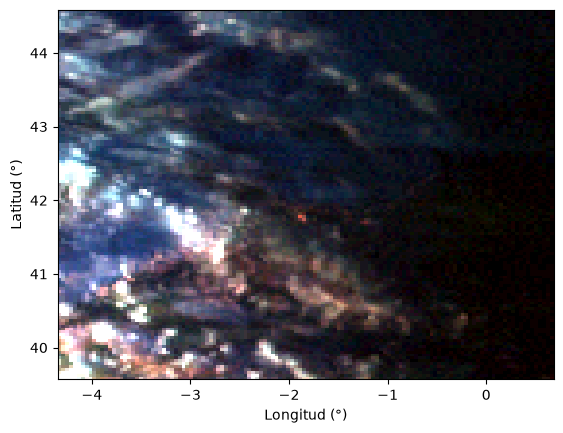

In [20]:
plot_rgb(satellite_crop, channels=COMPOSITES["natural_color"])

(<Axes: xlabel='Longitud (°)', ylabel='Latitud (°)'>,
 <matplotlib.collections.QuadMesh at 0x7b9921ff9e50>)

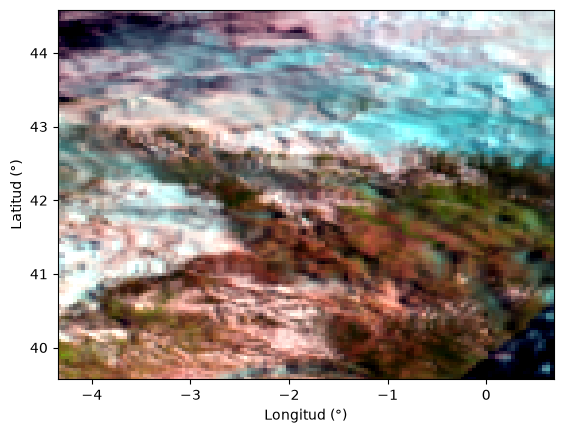

In [21]:
satellite_crop_early = dataset.sel(time=detected_round - pd.Timedelta(minutes=3*60), method="nearest")
satellite_crop_early = satellite_crop_early.sel(lon=slice(lon - CROP[0] / 2, lon + CROP[0] / 2),
                                               lat=slice(lat - CROP[1] / 2, lat + CROP[1] / 2))

plot_rgb(satellite_crop_early, channels=COMPOSITES["natural_color"])